# Week 1: Was Jamie Vardy's 2015/16 season luck?
**Question:** Leicester won the league and Vardy scored 24. Did he score more than his chances deserved (hot finishing), or did he just get a lot of good chances?

**Method:** compare his goals with his expected goals (xG). xG is the probability that an average player scores a given shot. Penalties are left out because they inflate both numbers.

**Data:** StatsBomb Open Data (Premier League 2015/16). The data is loaded live and not stored in this repo, as the StatsBomb User Agreement requires.

In [1]:
# Step 1: install the two libraries we need (Colab only needs this once per session)
!pip install -q statsbombpy mplsoccer

In [2]:
# Step 2: imports
import warnings
warnings.filterwarnings("ignore")      # statsbombpy prints a 'no credentials' warning; harmless for open data

import pandas as pd
import matplotlib.pyplot as plt
from statsbombpy import sb
from mplsoccer import VerticalPitch

In [3]:
# Step 3: find every Leicester match in Premier League 2015/16
# competition_id=2 is the Premier League, season_id=27 is 2015/16 (from sb.competitions())
matches = sb.matches(competition_id=2, season_id=27)
leicester = matches[(matches.home_team == "Leicester City") | (matches.away_team == "Leicester City")]
print(len(leicester), "Leicester matches")   # should print 38

38 Leicester matches


In [4]:
# Step 4: load the events for each match (one request per match, so this takes 1-2 minutes)
# then keep only Vardy's shots. Think of it as: SELECT * FROM events WHERE type='Shot' AND player='Jamie Vardy'
events = pd.concat([sb.events(match_id=m) for m in leicester.match_id])
shots = events[(events.type == "Shot") & (events.player == "Jamie Vardy")].copy()

# split out penalties
shots["is_goal"] = shots.shot_outcome == "Goal"
shots["is_pen"] = shots.shot_type == "Penalty"
np_shots = shots[~shots.is_pen]          # ~ means NOT, so this is non-penalty shots

summary = {
    "shots (all)": len(shots),
    "goals (all)": int(shots.is_goal.sum()),
    "non-pen shots": len(np_shots),
    "non-pen goals": int(np_shots.is_goal.sum()),
    "non-pen xG": round(np_shots.shot_statsbomb_xg.sum(), 1),
    "xG per non-pen shot": round(np_shots.shot_statsbomb_xg.mean(), 3),
}
summary

{'shots (all)': 118,
 'goals (all)': 24,
 'non-pen shots': 112,
 'non-pen goals': 19,
 'non-pen xG': np.float64(17.6),
 'xG per non-pen shot': np.float64(0.157)}

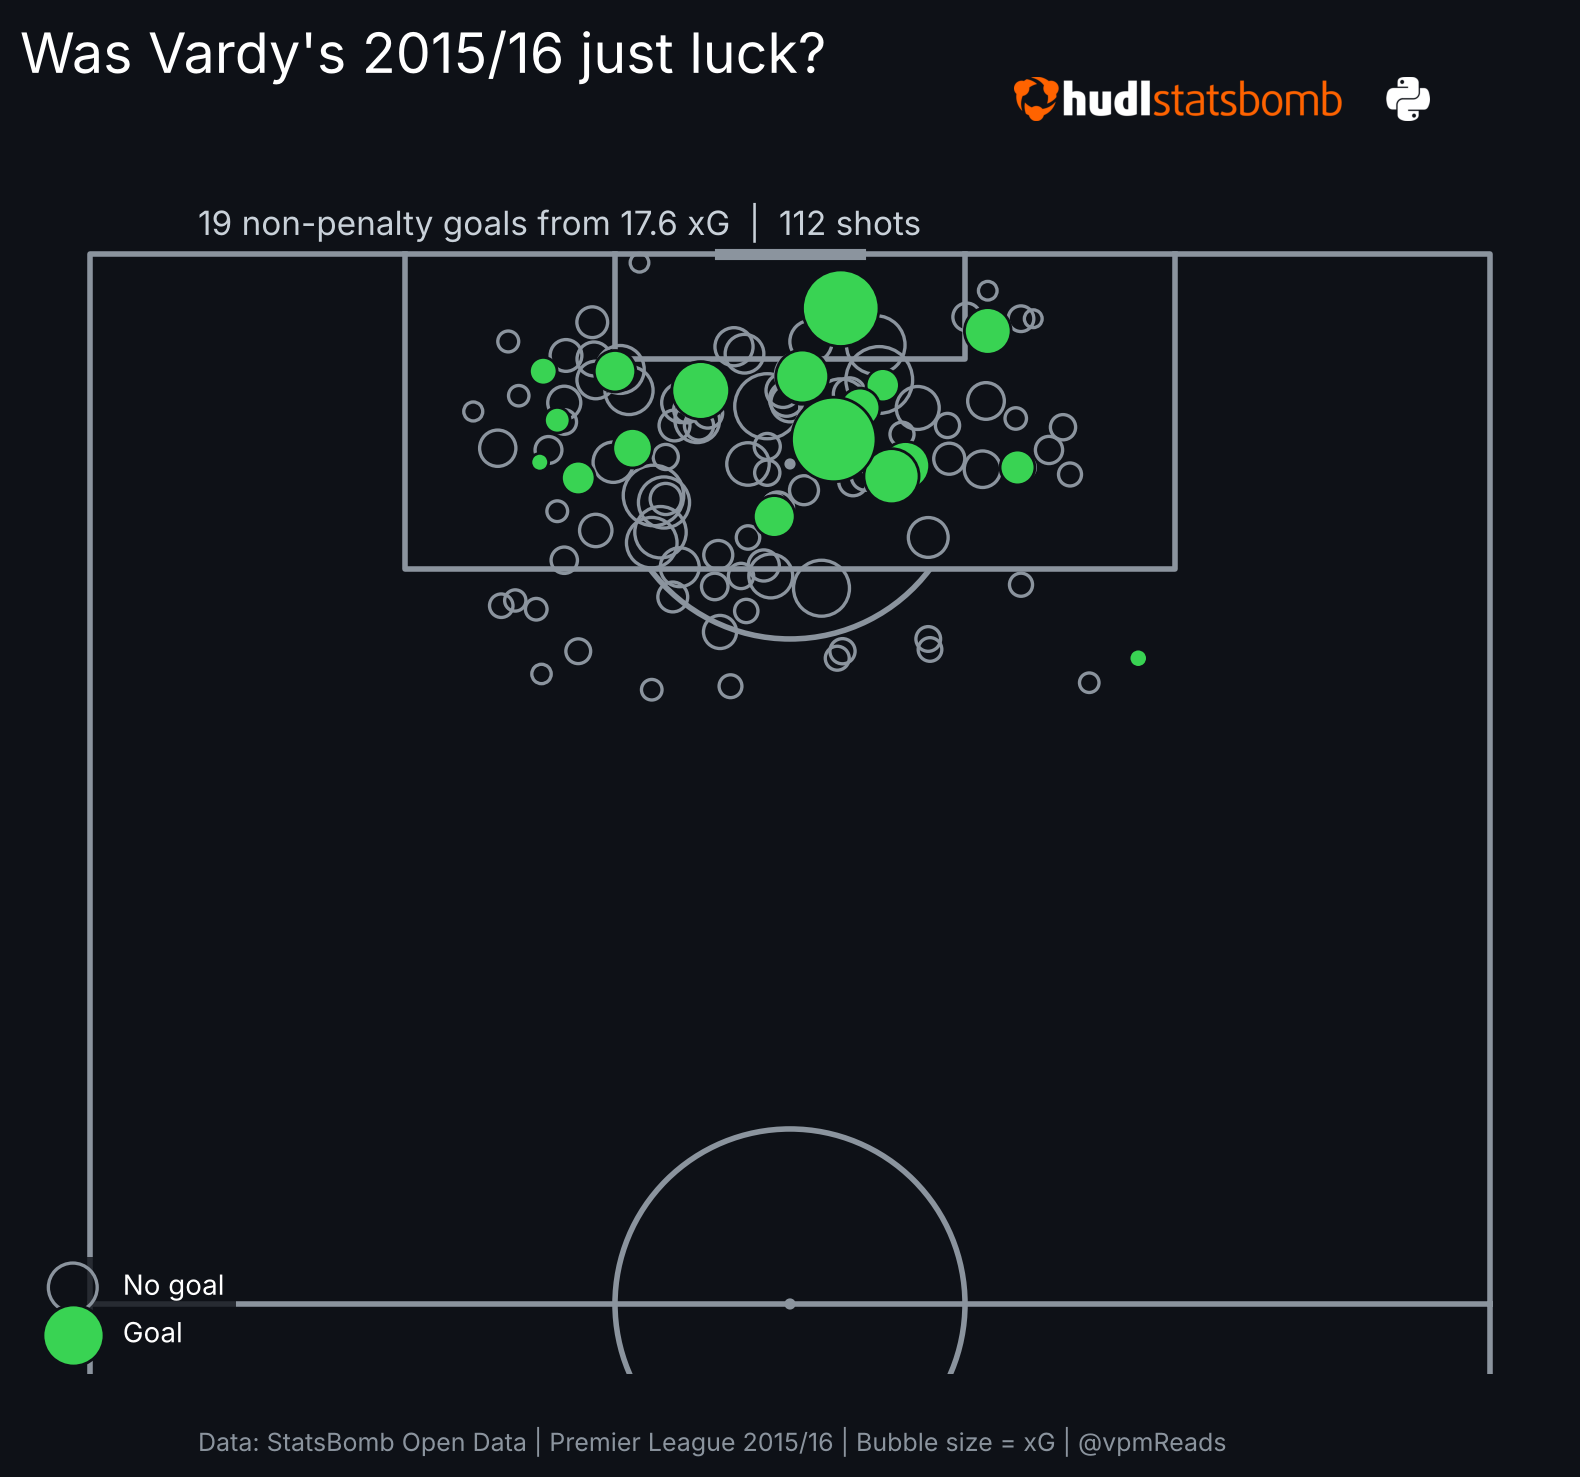

In [5]:
# Step 5: the chart: every non-penalty shot on half a pitch
# bubble size = xG (bigger = better chance), filled = goal, hollow = no goal
pitch = VerticalPitch(half=True, pitch_type="statsbomb", pitch_color="#0e1117", line_color="#8b949e")
fig, ax = pitch.draw(figsize=(8, 8))
fig.set_facecolor("#0e1117")

# StatsBomb location is a list [x, y]; split it into two columns
np_shots[["x", "y"]] = pd.DataFrame(np_shots.location.tolist(), index=np_shots.index)
goals, misses = np_shots[np_shots.is_goal], np_shots[~np_shots.is_goal]

pitch.scatter(misses.x, misses.y, s=misses.shot_statsbomb_xg * 900 + 30,
              facecolors="none", edgecolors="#8b949e", linewidth=1.2, ax=ax, label="No goal")
pitch.scatter(goals.x, goals.y, s=goals.shot_statsbomb_xg * 900 + 30,
              color="#39d353", edgecolors="#0e1117", ax=ax, label="Goal")

# title: the question, then the answer in numbers
ax.set_title("Was Vardy's 2015/16 just luck?", color="white", fontsize=20, pad=40, loc="left")
fig.text(0.13, 0.84,
         f"{summary['non-pen goals']} non-penalty goals from {summary['non-pen xG']} xG  |  "
         f"{summary['non-pen shots']} shots",
         color="#c9d1d9", fontsize=12)
ax.legend(loc="lower left", facecolor="#0e1117", edgecolor="none", labelcolor="white")

# credit line (required by the StatsBomb User Agreement)
fig.text(0.13, 0.08, "Data: StatsBomb Open Data | Premier League 2015/16 | Bubble size = xG | @vpmReads",
         color="#8b949e", fontsize=9)

# StatsBomb logo (the User Agreement requires it). Upload the logo as statsbomb_logo.png to Colab first.
import os
if os.path.exists("statsbomb_logo.png"):
    logo = plt.imread("statsbomb_logo.png")
    # [left, bottom, width, height] as fractions of the figure: top-right, beside the title
    logo_ax = fig.add_axes([0.64, 0.905, 0.26, 0.04])
    logo_ax.imshow(logo)
    logo_ax.axis("off")
else:
    print("Logo missing: add statsbomb_logo.png before posting")

plt.savefig("week01_vardy_xg.png", dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()

In [6]:
# Step 6: check every number used in the Insight below, so each claim is backed by code
# Penalty box in StatsBomb coordinates: x >= 102 and 18 <= y <= 62 (pitch is 120 x 80)
np_shots["in_box"] = (np_shots.x >= 102) & (np_shots.y >= 18) & (np_shots.y <= 62)
np_goals = np_shots[np_shots.is_goal]

# who made the final pass before each goal (the assist)? shot_key_pass_id links a shot to that pass
passer = events[events.type == "Pass"].set_index("id").player
assists = np_goals.shot_key_pass_id.map(passer).value_counts()

checks = {
    "shots in box": f"{int(np_shots.in_box.sum())} of {len(np_shots)}",
    "goals in box": f"{int(np_goals.in_box.sum())} of {len(np_goals)}",
    "xG in box": round(np_shots[np_shots.in_box].shot_statsbomb_xg.sum(), 1),
    "box shots per match": round(np_shots.in_box.sum() / len(leicester), 1),
    "goals from counters": int((np_goals.play_pattern == "From Counter").sum()),
    "penalties scored": f"{int(shots[shots.is_pen].is_goal.sum())} of {int(shots.is_pen.sum())}",
}
print(checks)
print("\nAssists for his non-penalty goals:")
print(assists)

{'shots in box': '91 of 112', 'goals in box': '18 of 19', 'xG in box': np.float64(16.0), 'box shots per match': np.float64(2.4), 'goals from counters': 5, 'penalties scored': '5 of 6'}

Assists for his non-penalty goals:
shot_key_pass_id
Riyad Mahrez           5
Danny Drinkwater       5
Andrej Kramarić        1
Christian Fuchs        1
José Leonardo Ulloa    1
Marc Albrighton        1
Nathan Dyer            1
Andrew Philip King     1
Demarai Gray           1
N''Golo Kanté          1
Name: count, dtype: int64


## Insight
- **Not luck.** 19 non-penalty goals from 17.6 xG: just 1.4 above what an average finisher scores from the same 112 shots. Normal variance, not a hot streak.
- **He lived in the box.** 91 of 112 shots and 18 of 19 goals came from inside it. 16.0 of his 17.6 xG was generated there.
- **The supply line.** Mahrez (5) and Drinkwater (5) assisted 10 of his 19 non-penalty goals. 5 goals came from counter-attacks.
- **So what:** Vardy didn't outrun his numbers; Leicester built a system that delivered him 2.4 box shots a game, and he converted at an honest rate. Add 5 penalties and you get 24.